# Cookie Cats A/B Testi — 04: Güç Analizi (Power Analysis)

**Notebook 03'ün sorusu:** "Gördüğümüz fark şanstan büyük mü?"
**Bu notebook'un sorusu:** "Deneyimiz, **gerçek bir fark olsaydı** onu yakalayabilecek kadar büyük müydü?"

İki tür hata yapabiliriz:

| | Gerçekte fark **yok** | Gerçekte fark **var** |
|---|---|---|
| Test "fark var" der | ❌ **Tip I hata** (yanlış alarm) — olasılığı α = %5 | ✅ Doğru tespit — olasılığı = **güç (power)** |
| Test "fark yok" der | ✅ Doğru | ❌ **Tip II hata** (kaçırma) — olasılığı β = 1 − güç |

**Güç = gerçek bir etkiyi yakalama olasılığı.** Sektör standardı: **%80**.

Bu notebook'ta üç soru cevaplıyoruz:
1. **MDE (minimum saptanabilir etki):** Bu büyüklükte bir deney, %80 olasılıkla en az ne kadarlık bir farkı yakalayabilir?
2. **Gereken örneklem:** Gördüğümüz büyüklükteki farkları güvenilir şekilde yakalamak için kaç oyuncu gerekirdi?
3. **Simülasyon:** Bunu formül yerine binlerce sahte deneyle doğrulayalım.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from scipy.stats import norm
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize, proportions_ztest

pd.set_option("display.float_format", "{:.4f}".format)
COLORS = {"retention_7": "#2a78d6", "retention_1": "#eb6834"}
SURFACE, INK, INK2, GRID = "#fcfcfb", "#1f1f1e", "#5f5e5a", "#e6e5e0"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "lines.linewidth": 2,
})
FIG = "../figures/"
ALPHA, POWER = 0.05, 0.80
Z_A, Z_B = norm.ppf(1 - ALPHA / 2), norm.ppf(POWER)   # 1.96 ve 0.84

df = pd.read_csv("../data/cookie_cats_clean.csv")
n30 = (df["version"] == "gate_30").sum()
n40 = (df["version"] == "gate_40").sum()
base = df[df["version"] == "gate_30"][["retention_1", "retention_7"]].mean()   # kontrol grubu oranları
obs = df.groupby("version")[["retention_1", "retention_7"]].mean().diff().loc["gate_40"]  # gözlenen fark
print(f"n: gate_30 = {n30}, gate_40 = {n40}")
print("Kontrol oranları:", base.round(4).to_dict())
print("Gözlenen fark (40 − 30, puan):", (obs * 100).round(2).to_dict())

n: gate_30 = 44699, gate_40 = 45489
Kontrol oranları: {'retention_1': 0.4482, 'retention_7': 0.1902}
Gözlenen fark (40 − 30, puan): {'retention_1': -0.59, 'retention_7': -0.82}


## 1. MDE: Bu deney en az ne kadarlık bir farkı yakalayabilir?

Sezgisel formül:

> **MDE ≈ (1.96 + 0.84) × standart hata ≈ 2.8 × SH**

- **1.96** → yanlış alarm riskini %5'te tutmak için gereken mesafe (notebook 03'teki "şans sınırı")
- **0.84** → gerçek etkiyi %80 olasılıkla o sınırın ötesine taşımak için gereken ek mesafe

Yani bir farkı **güvenilir şekilde** yakalamak için, farkın şans sınırını sadece geçmesi yetmez; rahatça geçmesi gerekir.

In [2]:
def se(p, n1, n2):
    return np.sqrt(p * (1 - p) * (1 / n1 + 1 / n2))

rows = []
for m in ["retention_7", "retention_1"]:
    s = se(base[m], n30, n40)
    mde = (Z_A + Z_B) * s
    rows.append({
        "metrik": m, "kontrol_oranı": base[m],
        "standart_hata_puan": s * 100,
        "şans_sınırı_puan (1.96×SH)": Z_A * s * 100,
        "MDE_puan (2.8×SH)": mde * 100,
        "MDE_göreli_%": mde / base[m] * 100,
        "gözlenen_fark_puan": abs(obs[m]) * 100,
    })
mde_tbl = pd.DataFrame(rows).set_index("metrik")
mde_tbl

,kontrol_oranı,standart_hata_puan,şans_sınırı_puan (1.96×SH),MDE_puan (2.8×SH),MDE_göreli_%,gözlenen_fark_puan
metrik,,,,,,
retention_7,0.1902,0.2614,0.5123,0.7322,3.8502,0.8183
retention_1,0.4482,0.3312,0.6492,0.9279,2.0703,0.5915


**Yorum:**
- **retention_7:** Gözlenen fark (0.82 puan) MDE'nin (0.73 puan) **üstünde**. Deney bu büyüklükte bir etkiyi yakalamaya yeterliydi.
- **retention_1:** Gözlenen fark (0.59 puan) MDE'nin (0.93 puan) **altında**. Notebook 03'teki "anlamlı değil" sonucu "etki yok" anlamına gelmiyor; deney bu büyüklükte bir farkı görecek kadar hassas değildi, yani örneklem yetersizdi.

## 2. Güç eğrisi: Gerçek fark X olsaydı, yakalama olasılığımız ne olurdu?

Mevcut örneklem büyüklüğüyle, olası her gerçek fark için gücü hesaplıyoruz.

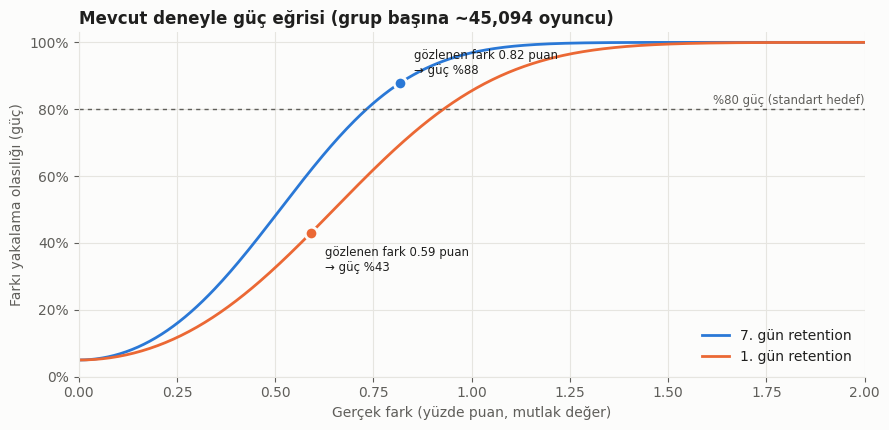

In [3]:
def power_at(diff, p, n1, n2):
    s = se(p, n1, n2)
    return norm.cdf(np.abs(diff) / s - Z_A) + norm.cdf(-np.abs(diff) / s - Z_A)

d = np.linspace(0, 0.02, 400)
fig, ax = plt.subplots(figsize=(9, 4.4))
for m, lbl in [("retention_7", "7. gün retention"), ("retention_1", "1. gün retention")]:
    pw = power_at(d, base[m], n30, n40)
    ax.plot(d * 100, pw, color=COLORS[m], linewidth=2, label=lbl)
    o = abs(obs[m]); po = power_at(o, base[m], n30, n40)
    ax.plot(o * 100, po, "o", color=COLORS[m], markersize=9, markeredgecolor=SURFACE, markeredgewidth=2, zorder=5)
    ax.annotate(f"gözlenen fark {o*100:.2f} puan\n→ güç %{po*100:.0f}", (o * 100, po),
                xytext=(10, -28 if m == "retention_1" else 6), textcoords="offset points", fontsize=8.5, color=INK)
ax.axhline(POWER, color=INK2, linewidth=1, linestyle=(0, (3, 3)))
ax.text(2.0, POWER + 0.015, "%80 güç (standart hedef)", ha="right", fontsize=8.5, color=INK2)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlim(0, 2.0); ax.set_ylim(0, 1.03)
ax.set_xlabel("Gerçek fark (yüzde puan, mutlak değer)")
ax.set_ylabel("Farkı yakalama olasılığı (güç)")
ax.set_title(f"Mevcut deneyle güç eğrisi (grup başına ~{(n30+n40)//2:,} oyuncu)")
ax.legend(loc="lower right")
fig.tight_layout(); fig.savefig(FIG + "07_guc_egrisi.png", dpi=150, bbox_inches="tight"); plt.show()

⚠️ **Mülakat notu (post-hoc power tuzağı):** Gözlenen farkı alıp "deneyin gücü %X'miş" demek tartışmalı bir pratiktir; bu "gözlenen güç", p-değerinin başka bir ifadesinden ibarettir ve yeni bilgi vermez. Güç analizinin asıl yeri **deneyden önce**dir: "İş açısından önemli olan en küçük fark ne? Onu yakalamak için kaç oyuncu lazım?" Bu notebook'ta gözlenen farkları sadece **referans nokta** olarak kullanıyoruz; asıl çıkarım MDE'den gelir.

## 3. Gereken örneklem büyüklüğü

Gözlenen büyüklükteki bir farkı %80 güçle yakalamak için grup başına kaç oyuncu gerekirdi? (`statsmodels` ile, Cohen's h etki büyüklüğü kullanılarak)

In [4]:
analysis = NormalIndPower()
rows = []
for m in ["retention_7", "retention_1"]:
    p1 = base[m]
    for label, diff in [("gözlenen fark", abs(obs[m])), ("0.5 puan", 0.005), ("1 puan", 0.01)]:
        h = proportion_effectsize(p1, p1 - diff)
        n_req = analysis.solve_power(effect_size=h, alpha=ALPHA, power=POWER, ratio=1, alternative="two-sided")
        rows.append({"metrik": m, "hedef fark": label, "fark_puan": diff * 100,
                     "grup_başına_gereken_n": int(np.ceil(n_req)), "mevcut_n": int(min(n30, n40)),
                     "yeterli_mi": n_req <= min(n30, n40)})
pd.DataFrame(rows).set_index(["metrik", "hedef fark"])

fark_puan  grup_başına_gereken_n  mevcut_n  \
metrik      hedef fark                                                  
retention_7 gözlenen fark     0.8183                  35502     44699   
            0.5 puan          0.5000                  95727     44699   
            1 puan            1.0000                  23683     44699   
retention_1 gözlenen fark     0.5915                 110814     44699   
            0.5 puan          0.5000                 155125     44699   
            1 puan            1.0000                  38737     44699   

                           yeterli_mi  
metrik      hedef fark                 
retention_7 gözlenen fark        True  
            0.5 puan            False  
            1 puan               True  
retention_1 gözlenen fark       False  
            0.5 puan            False  
            1 puan               True

**Yorum:** retention_1'deki 0.59 puanlık farkı %80 güçle yakalamak için grup başına ~111 bin oyuncu gerekirdi; bu, mevcut deneyin (~45 bin) yaklaşık **2.5 katı**. Bu yüzden ürün ekibine "retention_1'de etki yok" demem; *"retention_1'deki olası küçük bir etkiyi gözlemlemek için yeterli örneklem yoktu"* derim.

## 4. Simülasyonla doğrulama

Formülleri kullanmadan: gerçek farkın **bildiğimiz** bir değer olduğu 2.000 sahte deney üretiyoruz ve kaçında testin "anlamlı" dediğini sayıyoruz. Bu oran = güç.

Senaryolar:
- **Fark yok (0):** "anlamlı" oranı ≈ %5 olmalı (yanlış alarm oranı = α)
- **Gözlenen farklar:** "anlamlı" oranı yukarıdaki güç eğrisiyle tutarlı olmalı

In [5]:
rng = np.random.default_rng(7)
N_SIM = 2_000

def simulate(p_ctrl, diff, n1=n30, n2=n40, n_sim=N_SIM):
    x1 = rng.binomial(n1, p_ctrl, n_sim)            # kontrol grubunda dönen oyuncu sayısı
    x2 = rng.binomial(n2, p_ctrl - diff, n_sim)     # test grubunda dönen oyuncu sayısı
    p_vals = np.array([proportions_ztest([a, b], [n1, n2])[1] for a, b in zip(x1, x2)])
    return (p_vals < ALPHA).mean()

sim = []
for m in ["retention_7", "retention_1"]:
    for label, diff in [("fark yok", 0.0), ("gözlenen fark", abs(obs[m]))]:
        sim.append({"metrik": m, "senaryo": label, "gerçek_fark_puan": diff * 100,
                    "simülasyon: 'anlamlı' oranı": simulate(base[m], diff),
                    "formül: güç": ALPHA if diff == 0 else power_at(diff, base[m], n30, n40)})
pd.DataFrame(sim).set_index(["metrik", "senaryo"])

gerçek_fark_puan  simülasyon: 'anlamlı' oranı  \
metrik      senaryo                                                        
retention_7 fark yok                 0.0000                       0.0485   
            gözlenen fark            0.8183                       0.8855   
retention_1 fark yok                 0.0000                       0.0490   
            gözlenen fark            0.5915                       0.4470   

                           formül: güç  
metrik      senaryo                     
retention_7 fark yok            0.0500  
            gözlenen fark       0.8792  
retention_1 fark yok            0.0500  
            gözlenen fark       0.4310

**Yorum:** "Fark yok" senaryosunda anlamlı sonuç oranı ~%5 çıkıyor, çünkü α = 0.05 tam olarak bunu tanımlar: gerçekte fark yokken testin yanlışlıkla "fark var" deme olasılığı (Tip I hata oranı). Simülasyondaki %4.9, testin yanlış alarm oranını ayarladığımız gibi tuttuğunu doğruluyor.

## Güç analizi özeti

- Bu deney (grup başına ~45 bin oyuncu), retention_7'de en az **0.73 puanlık** (göreli **%3.9**) bir farkı %80 güçle yakalayabilirdi. Gözlenen fark **0.82 puan** → deney bu fark için **yeterli** (güç ≈ %88).
- retention_1'de MDE **0.93 puan**, gözlenen fark **0.59 puan** → "anlamlı değil" sonucu "etki yok" değil, **"deney bu büyüklükte bir etkiyi yakalayacak kadar hassas değildi"** olarak yorumlanmalı.
- **Bir sonraki deneyi tasarlasaydım:** iş açısından önemli MDE'yi önceden belirler, örneklem ve süreyi buna göre hesaplar, SRM'yi deney başından izler, level ve gelir verisini de toplardım.